# Demanda de Inventario de Grupo Bimbo con SVM (Máquinas de Soporte Vectorial)

En la práctica anterior predijimos la demanda con un **LSTM**. Ahora hacemos lo mismo con una **SVM**. Para que los dos modelos se puedan comparar, todo lo demás se queda igual:

* Las mismas series **Agencia × Producto** (las que tienen las 7 semanas completas).
* Las mismas variables, incluidas las temporales (media móvil y cambio %).
* La misma división: entrenamiento hasta la semana 7, **validación en la semana 8** y **prueba en la semana 9**.
* La misma métrica: **RMSE en unidades reales** y el mismo modelo ingenuo de referencia.

# Mapa del cuaderno

| Parte | Qué se hace | Dataset usado |
|---|---|---|
| 1. Carga de datos | Leer `train.csv`, `producto_tabla` y `cliente_tabla` | Completo (74M filas) |
| 2. Secuencias de tiempo | Series Agencia × Producto, variables temporales y ventanas | Completo (agregado) |
| 3. Modelo SVM y finetuning | SVR, ventana de 1 vs 3 semanas, ajuste de C y gamma, comparación de kernels (linear, poly, rbf, sigmoid) | Completo (agregado) |
| 4. Funciones de predicción | Predecir la demanda de un producto en una semana | Completo (agregado) |

# Parte 1. Carga de datos

**Dataset usado: completo (74M filas).**

In [1]:
import matplotlib.pyplot as plt
import pandas as pd 
import numpy as np
import copy
import os
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [2]:
dtypes = { #bajar la memoria de los datos para mejorar la lectura de datos 
    'Semana': 'int8',
    'Agencia_ID': 'int16',
    'Canal_ID': 'int8',
    'Ruta_SAK': 'int32',
    'Cliente_ID': 'int32',
    'Producto_ID': 'int32',
    'Venta_uni_hoy': 'int32',
    'Venta_hoy': 'float32',
    'Dev_uni_proxima': 'int32',
    'Dev_proxima': 'float32',
    'Demanda_uni_equil': 'int32'
}

productos = pd.read_csv("../data/raw/producto_tabla.csv") 
clientes = pd.read_csv("../data/raw/cliente_tabla.csv")

df = pd.read_csv("../data/raw/train.csv", dtype=dtypes) #nrows=3_000_000) #May change | skiprows=range(1, 50_000_001), , nrows=6_000_000

In [3]:
#Presentar: Cuantas valores hay en cada semana antes de cambiarlo:
listita = df['Semana'].unique()
for i in range(2,11):
    print( f" Semana {i} tiene: {(df['Semana'] == i).sum()} registros")

 Semana 2 tiene: 0 registros
 Semana 3 tiene: 11165207 registros
 Semana 4 tiene: 11009593 registros
 Semana 5 tiene: 10615397 registros
 Semana 6 tiene: 10191837 registros
 Semana 7 tiene: 10382849 registros
 Semana 8 tiene: 10406868 registros
 Semana 9 tiene: 10408713 registros
 Semana 10 tiene: 0 registros


In [4]:
df.head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
0,3,1110,7,3301,15766,1212,3,25.139999,0,0.0,3
1,3,1110,7,3301,15766,1216,4,33.520000,0,0.0,4
2,3,1110,7,3301,15766,1238,4,39.320000,0,0.0,4
3,3,1110,7,3301,15766,1240,4,33.520000,0,0.0,4
4,3,1110,7,3301,15766,1242,3,22.920000,0,0.0,3


In [5]:
trainCliente = df['Cliente_ID'].nunique()
trainProducto = df['Producto_ID'].nunique()
print(f"Numero de valores unicos Cliente_ID en train: {trainCliente}") 
print(f"Numero de valores unicos Producto_ID en train: {trainProducto}")
print(df.shape[0])

Numero de valores unicos Cliente_ID en train: 880604
Numero de valores unicos Producto_ID en train: 1799
74180464


In [6]:
print(df.columns)
#Variables categoricas:
varCatNominal = ['Semana', 'Agencia_ID', 'Canal_ID', 'Ruta_SAK']
# Cliente_ID y Producto_ID tambien son categoricas nominales, 
#pero por la cantidad de datos no se procesaran, se usaran otros metodos.

#Variables Numericas:
varNumericas = ["Venta_uni_hoy", "Venta_hoy","Dev_uni_proxima", "Dev_proxima", "Demanda_uni_equil"]

Index(['Semana', 'Agencia_ID', 'Canal_ID', 'Ruta_SAK', 'Cliente_ID',
       'Producto_ID', 'Venta_uni_hoy', 'Venta_hoy', 'Dev_uni_proxima',
       'Dev_proxima', 'Demanda_uni_equil'],
      dtype='object')


# Parte 2. Secuencias de tiempo

**Dataset usado: completo, agregado por Agencia × Producto × Semana.**

Igual que con el LSTM: sumamos la demanda de todos los clientes de una agencia para cada producto y semana. Una serie es, por ejemplo, *"el Pan Blanco de la agencia 1110 de la semana 3 a la 9"*. Los 74M de filas se convierten en unas 54 mil series y nos quedamos solo con las que tienen las 7 semanas completas.

In [7]:
# Variables que sumamos por semana (una fila por Agencia x Producto x Semana)
cols = ['Venta_uni_hoy', 'Venta_hoy', 'Dev_uni_proxima', 'Dev_proxima', 'Demanda_uni_equil']
semanas = list(range(3, 10))

agg = df.groupby(['Agencia_ID', 'Producto_ID', 'Semana'])[cols].sum().astype('float64')

agg.head()

Venta_uni_hoy   Venta_hoy  Dev_uni_proxima  \
Agencia_ID Producto_ID Semana                                               
1110       73          3                18.0  383.760010              0.0   
                       4                24.0  511.679993              0.0   
                       5                13.0  277.160004              2.0   
                       6                 6.0  127.919998              0.0   
                       7                36.0  767.519958              0.0   

                               Dev_proxima  Demanda_uni_equil  
Agencia_ID Producto_ID Semana                                  
1110       73          3          0.000000               18.0  
                       4          0.000000               24.0  
                       5         42.639999               12.0  
                       6          0.000000                6.0  
                       7          0.000000               36.0

In [8]:
# Una fila por serie (Agencia, Producto) y una columna por (variable, semana)
wide = agg.unstack('Semana')
wide = wide.dropna()  # nos quedamos con las series que tienen las 7 semanas
wide = wide.reindex(columns=pd.MultiIndex.from_product([cols, semanas]))
print(f"Series con las 7 semanas: {wide.shape[0]}")

Series con las 7 semanas: 53714


In [9]:
# Asi se ve la demanda de algunas series: una fila por (Agencia, Producto) y una columna por semana
wide['Demanda_uni_equil'].head()
#MultiIndex o índice jerárquico.

3      4       5       6      7      8      9
Agencia_ID Producto_ID                                                   
1110       73            18.0   24.0    12.0     6.0   36.0   36.0   36.0
           108          656.0  584.0   552.0   268.0  504.0  745.0  688.0
           145          849.0  748.0  1126.0  1347.0  938.0  594.0  685.0
           202          666.0  647.0   644.0   607.0  566.0  642.0  676.0
           205          128.0  109.0   105.0   136.0  132.0  123.0  141.0

## 2.1 Variables temporales (Feature Engineering para el modelo)

Son las mismas de la práctica del LSTM. El dataset no tiene fechas, solo el número de semana, así que las variables temporales salen del historial de cada serie:

| Variable | Qué mide | Ejemplo (demanda 100, 120, 90) |
|---|---|---|
| Semana anterior | La demanda de la última semana | 90 |
| Media móvil (3 semanas) | El promedio de las últimas 3 semanas | (100+120+90)/3 = 103.3 |
| Cambio % | Cuánto subió o bajó respecto a la semana anterior | (90−120)/120 = −25% |

In [10]:
# Demanda en unidades: matriz de (series, 7 semanas)
demanda = wide['Demanda_uni_equil'].values

# Media movil: promedio de la semana actual y las 2 anteriores
# (en las primeras semanas se promedia lo que haya: la semana 3 sola, luego 3 y 4, ...)
media_movil = np.zeros_like(demanda)
for t in range(demanda.shape[1]):
    inicio = max(0, t - 2)
    media_movil[:, t] = demanda[:, inicio:t + 1].mean(axis=1)

# Cambio %: (semana actual - semana anterior) / semana anterior
# La semana 3 no tiene semana anterior, asi que su cambio queda en 0
cambio_pct = np.zeros_like(demanda)
for t in range(1, demanda.shape[1]):
    anterior = demanda[:, t - 1]
    actual = demanda[:, t]
    # Si la semana anterior fue 0 no se puede dividir: dejamos el cambio en 0
    cambio_pct[:, t] = np.where(anterior > 0, (actual - anterior) / np.maximum(anterior, 1), 0)

# Recortamos los valores extremos (ej. pasar de 1 a 500 unidades = +49,900%)
# para que no dominen la normalizacion: el cambio queda entre -100% y +300%
cambio_pct = np.clip(cambio_pct, -1, 3)

print(f"Media movil: {media_movil.shape} | Cambio %: {cambio_pct.shape}")

Media movil: (53714, 7) | Cambio %: (53714, 7)


In [11]:
# Ejemplo con una serie: como quedan las variables temporales semana a semana
ejemplo = pd.DataFrame({
    'Demanda': demanda[0],
    'Media movil (3 sem)': media_movil[0].round(1),
    'Cambio %': (cambio_pct[0] * 100).round(1)
}, index=[f'Semana {s}' for s in semanas])

print(f"Serie: Agencia {wide.index[0][0]}, Producto {wide.index[0][1]}")
ejemplo

Serie: Agencia 1110, Producto 73


,Demanda,Media movil (3 sem),Cambio %
Semana 3,18.0,18.0,0.0
Semana 4,24.0,21.0,33.3
Semana 5,12.0,18.0,-50.0
Semana 6,6.0,14.0,-50.0
Semana 7,36.0,18.0,300.0
Semana 8,36.0,26.0,0.0
Semana 9,36.0,36.0,0.0


## 2.2 Normalización

Juntamos las 5 columnas originales con las 2 variables temporales y normalizamos todo entre 0 y 1. El *scaler* se ajusta solo con las semanas 3 a 8: la semana 9 es la prueba final y el modelo no debe conocerla de antemano.

Para la SVM normalizar es **todavía más importante** que para el LSTM: la SVM mide distancias entre ejemplos, así que si una variable está en pesos (miles) y otra en porcentaje, la de pesos dominaría todo.

In [12]:
from sklearn.preprocessing import MinMaxScaler

DEM = 4    # posicion de Demanda_uni_equil dentro de cols
N_SEM = 3  # semanas que mira el modelo

# Forma: (series, 7 semanas, 5 variables)
datos = wide.values.reshape(len(wide), len(cols), len(semanas)).transpose(0, 2, 1)

# log1p: la demanda tiene cola muy larga; asi la normalizacion no se aplasta
datos = np.log1p(datos)

# Agregamos las 2 variables temporales -> forma (series, 7 semanas, 7 variables)
# La media movil esta en unidades, asi que tambien lleva log1p. El cambio % ya es un numero pequeno
datos = np.concatenate([datos,
                        np.log1p(media_movil)[:, :, np.newaxis],
                        cambio_pct[:, :, np.newaxis]], axis=2)
nombres_variables = cols + ['Media_movil', 'Cambio_pct']
print(f"Forma de los datos: {datos.shape}  ->  variables: {nombres_variables}")

# Normalizamos (0-1) ajustando solo con las semanas de entrenamiento (3 a 8)
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(datos[:, :6, :].reshape(-1, datos.shape[2]))
datos_esc = scaler.transform(datos.reshape(-1, datos.shape[2])).reshape(datos.shape)

Forma de los datos: (53714, 7, 7)  ->  variables: ['Venta_uni_hoy', 'Venta_hoy', 'Dev_uni_proxima', 'Dev_proxima', 'Demanda_uni_equil', 'Media_movil', 'Cambio_pct']


## 2.3 Ventanas de tiempo y división en entrenamiento, validación y prueba

Cada ejemplo es: **entrada = las N semanas anteriores**, **salida = la demanda de la semana siguiente**. La división es la misma que con el LSTM:

| Ventana | Entrenamiento (semanas objetivo) | Validación | Prueba |
|---|---|---|---|
| 1 semana | 4, 5, 6, 7 | 8 | 9 |
| 3 semanas | 6, 7 | 8 | 9 |

**Lo único que cambia: la forma de la entrada.** El LSTM recibe una secuencia en 3D y la SVM una tabla en 2D, porque no entiende el orden del tiempo: solo ve una fila de números. Por eso "aplanamos" las semanas de la ventana en una sola fila:

| Modelo | Forma de X (ventana 3, 7 variables) | Qué ve |
|---|---|---|
| LSTM | (ejemplos, 3, 7) | 3 pasos de tiempo con 7 variables cada uno |
| SVM | (ejemplos, 21) | 21 columnas: las 7 variables de la semana 1, luego las de la semana 2 y luego las de la semana 3 |

In [13]:
# Entrada = N semanas anteriores, salida = demanda de la semana siguiente
# n_sem y variables son parametros, para poder probar ventana de 1 y de 3,
# y para probar el modelo con y sin las variables temporales
def ventanas(datos_esc, semanas_objetivo, n_sem=N_SEM, variables=None):
    if variables is None:
        variables = list(range(datos_esc.shape[2]))  # todas las variables
    X = np.concatenate([datos_esc[:, (s-3)-n_sem:(s-3), :][:, :, variables] for s in semanas_objetivo])
    y = np.concatenate([datos_esc[:, s-3, DEM] for s in semanas_objetivo])
    return X, y

# NUEVO: la SVM necesita una tabla 2D, asi que aplanamos (ejemplos, semanas, variables) -> (ejemplos, semanas x variables)
def ventanas_svm(datos_esc, semanas_objetivo, n_sem=N_SEM, variables=None):
    X, y = ventanas(datos_esc, semanas_objetivo, n_sem, variables)
    return X.reshape(len(X), -1), y

# Semanas objetivo de entrenamiento segun el tamano de la ventana
# (la primera semana que se puede predecir es 3 + n_sem; la 8 queda para validacion)
def semanas_entrenamiento(n_sem):
    return list(range(3 + n_sem, 8))

SEMANA_VAL = 8
SEMANA_TEST = 9

VARS_ORIGINALES = [0, 1, 2, 3, 4]               # las 5 columnas de cols
VARS_CON_TEMPORALES = [0, 1, 2, 3, 4, 5, 6]     # + Media_movil y Cambio_pct

for n in [1, 3]:
    X_3d, _ = ventanas(datos_esc, semanas_entrenamiento(n), n)
    X_2d, _ = ventanas_svm(datos_esc, semanas_entrenamiento(n), n)
    print(f"Ventana de {n}: entrena con semanas {semanas_entrenamiento(n)} -> "
          f"LSTM {X_3d.shape} | SVM {X_2d.shape}")

Ventana de 1: entrena con semanas [4, 5, 6, 7] -> LSTM (214856, 1, 7) | SVM (214856, 7)
Ventana de 3: entrena con semanas [6, 7] -> LSTM (107428, 3, 7) | SVM (107428, 21)


In [14]:
# Comprobacion: la fila aplanada de la SVM tiene exactamente los mismos numeros que la secuencia del LSTM
X_3d, _ = ventanas(datos_esc, [SEMANA_VAL], 3)
X_2d, _ = ventanas_svm(datos_esc, [SEMANA_VAL], 3)
print("Misma informacion en 3D y en 2D:", np.array_equal(X_3d[0].ravel(), X_2d[0]))

Misma informacion en 3D y en 2D: True


# Parte 3. Modelo SVM y finetuning

**Dataset usado: completo, agregado.**

Como queremos predecir una **cantidad** (unidades) y no una clase, usamos **SVR** (*Support Vector Regression*), la versión de la SVM para regresión. En la práctica del crédito usamos `SVC` porque la salida era bueno/malo.

**¿Cómo funciona la SVR?** Busca una función que pase cerca de los puntos, pero ignora los errores pequeños: todo lo que cae dentro de un "tubo" de ancho **epsilon** alrededor de la predicción no se castiga. Solo los puntos que quedan fuera del tubo (los *vectores de soporte*) definen el modelo.

**Parámetros principales** (los mismos que vimos en clase):
* **kernel:** la forma de la función. `linear` es una recta (hiperplano); `rbf` permite relaciones no lineales.
* **C:** cuánto se castigan los errores fuera del tubo. C alto = se ajusta más al entrenamiento (riesgo de overfitting).
* **gamma:** solo para `rbf`. Qué tan lejos llega la influencia de cada punto. Gamma alto = curvas más "nerviosas".
* **epsilon:** el ancho del tubo. Lo dejamos en 0.01 porque la demanda está escalada entre 0 y 1 (el valor por defecto, 0.1, sería un 10% de todo el rango: demasiado grande).

**Métrica: RMSE** en unidades reales, igual que con el LSTM. **Modelo de referencia (ingenuo):** predecir que la próxima semana se demanda lo mismo que la semana anterior. Si la SVM no le gana a esto, no sirve.

In [15]:
from math import sqrt
from time import time
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error

# Regresamos de la escala 0-1 a unidades reales
def a_unidades(y_esc):
    y_log = y_esc * (scaler.data_max_[DEM] - scaler.data_min_[DEM]) + scaler.data_min_[DEM]
    return np.maximum(np.expm1(y_log), 0)

# RMSE en unidades reales (no en la escala 0-1)
def rmse_unidades(y_esc_real, y_esc_pred):
    return sqrt(mean_squared_error(a_unidades(y_esc_real), a_unidades(y_esc_pred)))

# Modelo ingenuo en validacion: la demanda de la semana 8 = la de la semana 7
val_X, val_y = ventanas(datos_esc, [SEMANA_VAL], 1)
rmse_ingenuo_val = rmse_unidades(val_y, val_X[:, -1, DEM])
print(f"RMSE ingenuo en validacion (semana 8): {rmse_ingenuo_val:.2f}")

RMSE ingenuo en validacion (semana 8): 690.28


## 3.1 Diseño del modelo

**Diferencia importante con el LSTM: el tamaño del entrenamiento.** El LSTM aprende por lotes (`batch_size=512`), así que puede usar todos los ejemplos. La SVR no: compara los ejemplos entre sí de dos en dos, así que el tiempo crece con el **cuadrado** de los datos. Con ventana de 1 hay unos 216 mil ejemplos de entrenamiento (54 mil series × 4 semanas) y la SVR tardaría horas.

Por eso **entrenamos con una muestra al azar de ejemplos** (`N_MUESTRA`). Ojo, no es lo mismo que la muestra del 3% de la práctica anterior:
* Aquí se eligen **ventanas ya armadas**, así que cada ejemplo conserva su historia completa (las series no se rompen).
* La muestra es **solo para entrenar**. La validación (semana 8) y la prueba (semana 9) se hacen con **todas** las series.
* Las dos ventanas usan el mismo tamaño de muestra, así la comparación es justa.

In [16]:
os.makedirs('figuras', exist_ok=True)  # aqui se guardan las graficas para las diapositivas

N_MUESTRA = 20_000  # ejemplos para entrenar en los experimentos (subirlo mejora un poco, pero tarda mas)

# Muestra al azar de ejemplos de entrenamiento (siempre la misma gracias a la semilla)
def muestra(X, y, n, semilla=42):
    if len(X) <= n:
        return X, y  # si hay menos ejemplos que n, se usan todos
    rng = np.random.default_rng(semilla)
    filas = rng.choice(len(X), size=n, replace=False)
    return X[filas], y[filas]

def crear_modelo(kernel='rbf', C=1.0, gamma='scale', epsilon=0.01):
    # SVR = SVM para regresion (predice un numero, no una clase)
    # cache_size: memoria (MB) para guardar calculos del kernel; acelera el entrenamiento
    return SVR(kernel=kernel, C=C, gamma=gamma, epsilon=epsilon, cache_size=1000)

def entrenar(n_sem, variables, kernel='rbf', C=1.0, gamma='scale', epsilon=0.01, n_muestra=N_MUESTRA):
    # Entrena con una muestra de las semanas de entrenamiento y mide el RMSE en validacion (semana 8)
    train_X, train_y = ventanas_svm(datos_esc, semanas_entrenamiento(n_sem), n_sem, variables)
    train_X, train_y = muestra(train_X, train_y, n_muestra)
    val_X, val_y = ventanas_svm(datos_esc, [SEMANA_VAL], n_sem, variables)

    inicio = time()
    model = crear_modelo(kernel, C, gamma, epsilon)
    model.fit(train_X, train_y)
    segundos = time() - inicio

    rmse_val = rmse_unidades(val_y, model.predict(val_X))
    return model, rmse_val, segundos

## 3.2 Experimento 1: ventana de 1 vs. 3 semanas, con y sin variables temporales

El mismo experimento que hicimos con el LSTM: entrenamos 4 SVR iguales (kernel `rbf`, C=1) cambiando solo dos cosas: cuántas semanas mira y si recibe las variables temporales. Se comparan con el RMSE de validación (semana 8).

In [17]:
opciones_variables = [('Originales (5)', VARS_ORIGINALES),
                      ('Con temporales (7)', VARS_CON_TEMPORALES)]

resultados_exp1 = []
for n_sem in [1, 3]:
    for nombre_vars, variables in opciones_variables:
        model, rmse_val, segundos = entrenar(n_sem, variables)
        resultados_exp1.append({'Ventana': n_sem, 'Variables': nombre_vars,
                                'Vectores de soporte': len(model.support_),
                                'Segundos': round(segundos, 1), 'RMSE validacion': round(rmse_val, 2)})
        print(f"Ventana {n_sem} | {nombre_vars} | RMSE validacion: {rmse_val:.2f} | {segundos:.1f} s")

tabla_exp1 = pd.DataFrame(resultados_exp1)
tabla_exp1

Ventana 1 | Originales (5) | RMSE validacion: 744.02 | 10.6 s
Ventana 1 | Con temporales (7) | RMSE validacion: 775.73 | 10.1 s
Ventana 3 | Originales (5) | RMSE validacion: 772.47 | 11.8 s
Ventana 3 | Con temporales (7) | RMSE validacion: 750.92 | 13.7 s


,Ventana,Variables,Vectores de soporte,Segundos,RMSE validacion
0,1,Originales (5),11751,10.6,744.02
1,1,Con temporales (7),11596,10.1,775.73
2,3,Originales (5),11419,11.8,772.47
3,3,Con temporales (7),11325,13.7,750.92


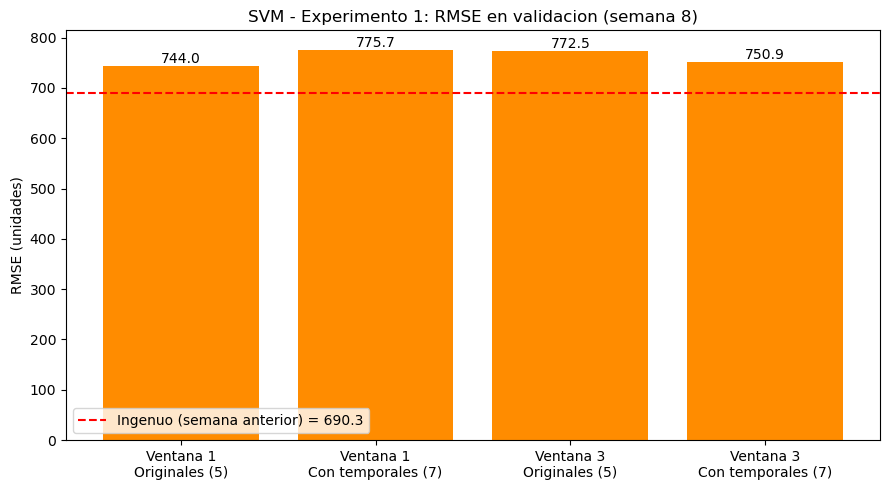

Mejor combinacion: ventana de 1 semana(s), variables Originales (5)


In [18]:
# Grafica del experimento 1 (para las diapositivas)
etiquetas = [f"Ventana {r['Ventana']}\n{r['Variables']}" for _, r in tabla_exp1.iterrows()]

plt.figure(figsize=(9, 5))
plt.bar(etiquetas, tabla_exp1['RMSE validacion'], color='darkorange')
plt.axhline(rmse_ingenuo_val, color='red', linestyle='--', label=f'Ingenuo (semana anterior) = {rmse_ingenuo_val:.1f}')
for i, valor in enumerate(tabla_exp1['RMSE validacion']):
    plt.text(i, valor, f'{valor:.1f}', ha='center', va='bottom')
plt.title('SVM - Experimento 1: RMSE en validacion (semana 8)')
plt.ylabel('RMSE (unidades)')
plt.legend()
plt.tight_layout()
plt.savefig('figuras/svm_exp1_ventana_variables.png', dpi=150)
plt.show()

# Nos quedamos con la combinacion de menor RMSE
mejor = tabla_exp1.loc[tabla_exp1['RMSE validacion'].idxmin()]
MEJOR_N_SEM = int(mejor['Ventana'])
MEJORES_VARS = VARS_ORIGINALES if mejor['Variables'] == 'Originales (5)' else VARS_CON_TEMPORALES
print(f"Mejor combinacion: ventana de {MEJOR_N_SEM} semana(s), variables {mejor['Variables']}")

## 3.3 Experimento 2: finetuning de hiperparámetros

Con la mejor ventana y el mejor grupo de variables probamos dos kernels, igual que en la práctica de clase con `GridSearchCV`:
* **linear** con C = 0.1, 1 y 10 (3 configuraciones; gamma no se usa en este kernel).
* **rbf** con C = 0.1, 1 y 10 × gamma = `scale`, 0.1 y 1 (9 configuraciones).

**¿Por qué no usamos `GridSearchCV` directamente?** Porque hace validación cruzada mezclando los ejemplos al azar, y aquí el orden del tiempo importa: no podemos validar con semanas anteriores a las que usamos para entrenar. Por eso hacemos el mismo recorrido de la grilla a mano, validando siempre con la semana 8.

`gamma='scale'` es el valor por defecto de scikit-learn: lo calcula a partir del número de variables y de su varianza.

In [19]:
# Grilla de configuraciones: (kernel, C, gamma)
grilla = [('linear', C, 'scale') for C in [0.1, 1, 10]] + \
         [('rbf', C, gamma) for C in [0.1, 1, 10] for gamma in ['scale', 0.1, 1]]
print(f"Configuraciones a probar: {len(grilla)}")

resultados_exp2 = []
for kernel, C, gamma in grilla:
    model, rmse_val, segundos = entrenar(MEJOR_N_SEM, MEJORES_VARS, kernel, C, gamma)
    resultados_exp2.append({'Kernel': kernel, 'C': C, 'Gamma': '-' if kernel == 'linear' else str(gamma),
                            'Vectores de soporte': len(model.support_),
                            'Segundos': round(segundos, 1), 'RMSE validacion': round(rmse_val, 2)})
    print(f"Kernel {kernel} | C {C} | Gamma {gamma} | RMSE validacion: {rmse_val:.2f} | {segundos:.1f} s")

tabla_exp2 = pd.DataFrame(resultados_exp2).sort_values('RMSE validacion').reset_index(drop=True)
tabla_exp2

Configuraciones a probar: 12
Kernel linear | C 0.1 | Gamma scale | RMSE validacion: 596.08 | 5.9 s
Kernel linear | C 1 | Gamma scale | RMSE validacion: 595.90 | 7.2 s
Kernel linear | C 10 | Gamma scale | RMSE validacion: 595.81 | 16.7 s
Kernel rbf | C 0.1 | Gamma scale | RMSE validacion: 901.57 | 8.8 s
Kernel rbf | C 0.1 | Gamma 0.1 | RMSE validacion: 587.50 | 8.6 s
Kernel rbf | C 0.1 | Gamma 1 | RMSE validacion: 645.13 | 8.9 s
Kernel rbf | C 1 | Gamma scale | RMSE validacion: 744.02 | 9.8 s
Kernel rbf | C 1 | Gamma 0.1 | RMSE validacion: 595.61 | 8.9 s
Kernel rbf | C 1 | Gamma 1 | RMSE validacion: 687.60 | 9.3 s
Kernel rbf | C 10 | Gamma scale | RMSE validacion: 897.23 | 16.2 s
Kernel rbf | C 10 | Gamma 0.1 | RMSE validacion: 583.49 | 9.6 s
Kernel rbf | C 10 | Gamma 1 | RMSE validacion: 969.74 | 11.9 s


,Kernel,C,Gamma,Vectores de soporte,Segundos,RMSE validacion
0,rbf,10.0,0.1,11777,9.6,583.49
1,rbf,0.1,0.1,11818,8.6,587.50
2,rbf,1.0,0.1,11797,8.9,595.61
3,linear,10.0,-,11889,16.7,595.81
4,linear,1.0,-,11891,7.2,595.90
5,linear,0.1,-,11888,5.9,596.08
6,rbf,0.1,1,11771,8.9,645.13
7,rbf,1.0,1,11724,9.3,687.60
8,rbf,1.0,scale,11751,9.8,744.02
9,rbf,10.0,scale,11786,16.2,897.23


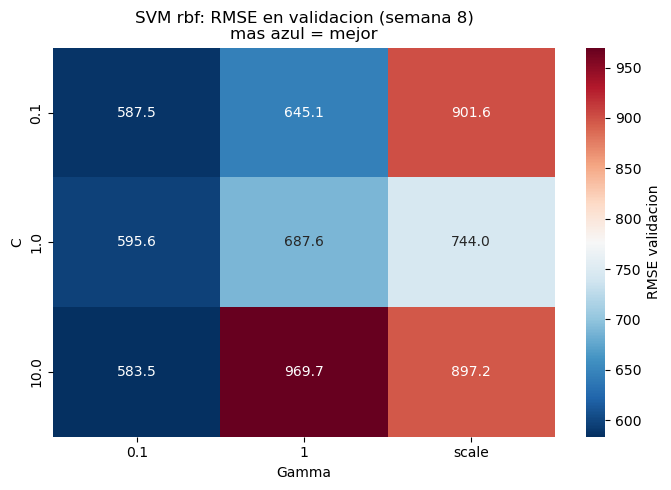

In [20]:
# Heatmap del kernel rbf: RMSE en validacion para cada C y gamma (como en la practica de clase)
tabla_rbf = tabla_exp2[tabla_exp2['Kernel'] == 'rbf']
matriz = tabla_rbf.pivot_table(index='C', columns='Gamma', values='RMSE validacion')

plt.figure(figsize=(7, 5))
sns.heatmap(matriz, annot=True, fmt='.1f', cmap='RdBu_r', cbar_kws={'label': 'RMSE validacion'})
plt.title('SVM rbf: RMSE en validacion (semana 8)\nmas azul = mejor')
plt.tight_layout()
plt.savefig('figuras/svm_heatmap_C_gamma.png', dpi=150)
plt.show()

In [21]:
# Mejor configuracion del finetuning (primera fila, porque la tabla esta ordenada)
mejor_conf = tabla_exp2.iloc[0]
MEJOR_KERNEL = mejor_conf['Kernel']
MEJOR_C = float(mejor_conf['C'])
MEJOR_GAMMA = mejor_conf['Gamma']
# gamma se guardo como texto para la tabla: lo regresamos a numero si no es 'scale'
if MEJOR_GAMMA in ['scale', '-']:
    MEJOR_GAMMA = 'scale'
else:
    MEJOR_GAMMA = float(MEJOR_GAMMA)
print(f"Modelo elegido: ventana {MEJOR_N_SEM}, {len(MEJORES_VARS)} variables, "
      f"kernel {MEJOR_KERNEL}, C {MEJOR_C}, gamma {MEJOR_GAMMA}")

Modelo elegido: ventana 1, 5 variables, kernel rbf, C 10.0, gamma 0.1


## 3.4 Experimento 3: comparación de kernels (y de otro modelo)

Aquí comparamos **los distintos kernels de la SVM** con la misma ventana, las mismas variables y la misma muestra. Para que sea una comparación simple y justa, todos usan los **valores por defecto** (C = 1, gamma = `scale`); solo cambia el kernel:

| Kernel | Qué forma tiene la función | Idea simple |
|---|---|---|
| `linear` | Una recta / hiperplano | La demanda sube o baja en proporción a las entradas |
| `poly` (grado 2) | Una curva tipo parábola | Permite una curvatura suave |
| `poly` (grado 3) | Una curva más flexible | Más curvas, más riesgo de sobreajuste |
| `rbf` | Curvas "locales" alrededor de cada punto | Muy flexible; depende mucho de gamma |
| `sigmoid` | Forma de "S" (como una neurona) | Casi nunca funciona bien en regresión; lo dejamos para comparar |

Además agregamos **otro modelo** como referencia: una **Regresión Lineal** normal (sin SVM). Si una SVM no le gana a una regresión lineal, la complejidad extra no vale la pena.

Nota: aquí no buscamos el mejor modelo (eso ya lo hizo el Experimento 2), solo **ver cómo cambia el error según el kernel**.


In [22]:
# Experimento 3: mismos datos para todos los modelos, solo cambia el kernel
train_X, train_y = ventanas_svm(datos_esc, semanas_entrenamiento(MEJOR_N_SEM), MEJOR_N_SEM, MEJORES_VARS)
train_X, train_y = muestra(train_X, train_y, N_MUESTRA)
val_X, val_y = ventanas_svm(datos_esc, [SEMANA_VAL], MEJOR_N_SEM, MEJORES_VARS)

# (nombre para la tabla, modelo). Todos con C=1 y gamma='scale' (valores por defecto)
modelos_exp3 = [
    ('SVM linear',         SVR(kernel='linear', C=1, epsilon=0.01, cache_size=1000)),
    ('SVM poly (grado 2)', SVR(kernel='poly', degree=2, coef0=1, C=1, epsilon=0.01, cache_size=1000)),
    ('SVM poly (grado 3)', SVR(kernel='poly', degree=3, coef0=1, C=1, epsilon=0.01, cache_size=1000)),
    ('SVM rbf',            SVR(kernel='rbf', C=1, epsilon=0.01, cache_size=1000)),
    ('SVM sigmoid',        SVR(kernel='sigmoid', C=1, epsilon=0.01, cache_size=1000)),
    ('Regresion Lineal',   LinearRegression()),  # otro modelo, sin SVM
]
# coef0=1 en poly: sin esto el kernel polinomial solo multiplica las variables y aprende muy mal

resultados_exp3 = []
for nombre, model in modelos_exp3:
    inicio = time()
    model.fit(train_X, train_y)
    segundos = time() - inicio
    # Recortamos la prediccion a la escala 0-1: algunos kernels (poly, sigmoid) pueden dar valores
    # muy fuera de rango y al regresar a unidades (expm1) se dispararian
    pred = np.clip(model.predict(val_X), 0, 1)
    rmse_val = rmse_unidades(val_y, pred)
    resultados_exp3.append({'Modelo': nombre, 'Segundos': round(segundos, 1), 'RMSE validacion': round(rmse_val, 2)})
    print(f"{nombre:20s} | RMSE validacion: {rmse_val:8.2f} | {segundos:.1f} s")

tabla_exp3 = pd.DataFrame(resultados_exp3).sort_values('RMSE validacion').reset_index(drop=True)
tabla_exp3


SVM linear           | RMSE validacion:   595.90 | 7.5 s
SVM poly (grado 2)   | RMSE validacion:   931.47 | 36.4 s
SVM poly (grado 3)   | RMSE validacion:   653.58 | 110.1 s
SVM rbf              | RMSE validacion:   744.02 | 9.8 s
SVM sigmoid          | RMSE validacion: 136183.99 | 14.7 s
Regresion Lineal     | RMSE validacion:   920.21 | 0.1 s


,Modelo,Segundos,RMSE validacion
0,SVM linear,7.5,595.90
1,SVM poly (grado 3),110.1,653.58
2,SVM rbf,9.8,744.02
3,Regresion Lineal,0.1,920.21
4,SVM poly (grado 2),36.4,931.47
5,SVM sigmoid,14.7,136183.99


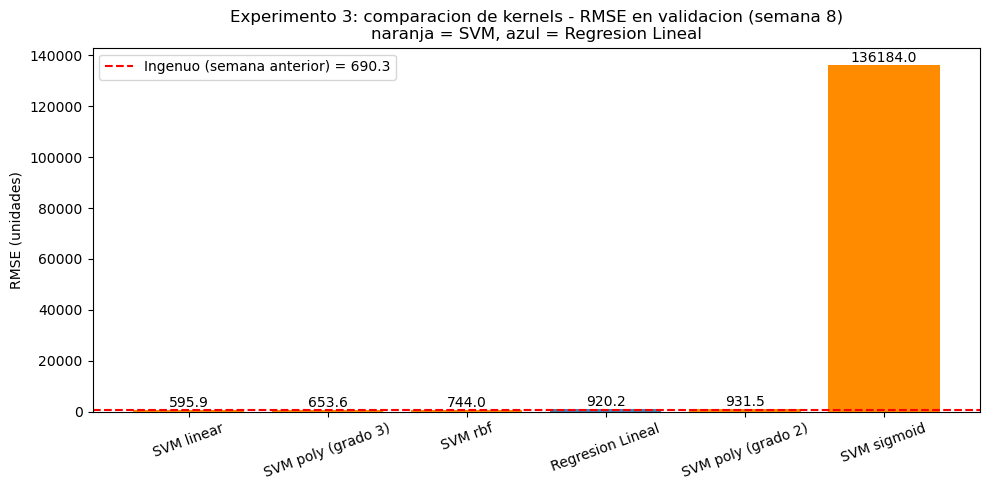

Mejor en esta comparacion: SVM linear (RMSE 595.90)
Peor en esta comparacion:  SVM sigmoid (RMSE 136183.99)


In [23]:
# Grafica del experimento 3 (para las diapositivas)
plt.figure(figsize=(10, 5))
colores = ['steelblue' if m == 'Regresion Lineal' else 'darkorange' for m in tabla_exp3['Modelo']]
plt.bar(tabla_exp3['Modelo'], tabla_exp3['RMSE validacion'], color=colores)
plt.axhline(rmse_ingenuo_val, color='red', linestyle='--', label=f'Ingenuo (semana anterior) = {rmse_ingenuo_val:.1f}')
for i, valor in enumerate(tabla_exp3['RMSE validacion']):
    plt.text(i, valor, f'{valor:.1f}', ha='center', va='bottom')
plt.title('Experimento 3: comparacion de kernels - RMSE en validacion (semana 8)\nnaranja = SVM, azul = Regresion Lineal')
plt.ylabel('RMSE (unidades)')
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.savefig('figuras/svm_exp3_kernels.png', dpi=150)
plt.show()

print(f"Mejor en esta comparacion: {tabla_exp3.iloc[0]['Modelo']} (RMSE {tabla_exp3.iloc[0]['RMSE validacion']:.2f})")
print(f"Peor en esta comparacion:  {tabla_exp3.iloc[-1]['Modelo']} (RMSE {tabla_exp3.iloc[-1]['RMSE validacion']:.2f})")


**Cómo leer este experimento:**

* Las barras más bajas son mejores (menos error). La línea roja es el modelo ingenuo: lo que quede por encima de ella **no sirve**.
* **linear** y la **Regresión Lineal** suelen quedar parecidas: las dos dibujan un hiperplano; la diferencia es que la SVR ignora los errores pequeños (el tubo epsilon) y es menos sensible a valores extremos.
* **poly** permite curvas, pero con grado alto puede sobreajustarse y tarda más en entrenar.
* **rbf con valores por defecto** puede salir peor que linear; en el Experimento 2 vimos que mejora mucho al ajustar **C** y **gamma**. Por eso el kernel solo no decide: también importan sus hiperparámetros.
* **sigmoid** casi siempre es el peor en regresión: es el kernel que menos se usa en la práctica.

El modelo final (siguiente sección) sigue siendo el que eligió el finetuning del Experimento 2.


## 3.5 Modelo final y evaluación en la semana 9 (prueba)

Ahora que ya elegimos todo, entrenamos el modelo final **sumando la semana 8 al entrenamiento** y con una muestra más grande (`N_MUESTRA_FINAL`), porque este modelo se entrena una sola vez. Después lo evaluamos **una sola vez** en la semana 9, con **todas** las series.

Si tienes el RMSE de la semana 9 del LSTM (de `Practica_DL_final`), ponlo en `RMSE_LSTM` para que aparezca en la comparación.

In [24]:
N_MUESTRA_FINAL = 40_000
RMSE_LSTM = None  # pon aqui el RMSE de la semana 9 del LSTM (ej. RMSE_LSTM = 123.45) para comparar

# Entrenamiento = semanas de entrenamiento + la semana 8
semanas_finales = semanas_entrenamiento(MEJOR_N_SEM) + [SEMANA_VAL]
train_X, train_y = ventanas_svm(datos_esc, semanas_finales, MEJOR_N_SEM, MEJORES_VARS)
train_X, train_y = muestra(train_X, train_y, N_MUESTRA_FINAL)
test_X, test_y = ventanas_svm(datos_esc, [SEMANA_TEST], MEJOR_N_SEM, MEJORES_VARS)
print(f"Entrena con semanas {semanas_finales}: {train_X.shape} | Prueba con semana {SEMANA_TEST}: {test_X.shape}")

inicio = time()
modelo_final = crear_modelo(MEJOR_KERNEL, MEJOR_C, MEJOR_GAMMA)
modelo_final.fit(train_X, train_y)
print(f"Entrenamiento listo en {time() - inicio:.1f} s | vectores de soporte: {len(modelo_final.support_)}")

Entrena con semanas [4, 5, 6, 7, 8]: (40000, 5) | Prueba con semana 9: (53714, 5)
Entrenamiento listo en 38.4 s | vectores de soporte: 23264


In [25]:
# Para el ingenuo necesitamos la demanda de la semana anterior (la semana 8), en la escala 0-1
test_X_3d, _ = ventanas(datos_esc, [SEMANA_TEST], 1)

y_real = a_unidades(test_y)
y_pred = a_unidades(modelo_final.predict(test_X))
y_base = a_unidades(test_X_3d[:, -1, DEM])  # modelo ingenuo: repetir la semana anterior

rmse_svm = sqrt(mean_squared_error(y_real, y_pred))
rmse_base = sqrt(mean_squared_error(y_real, y_base))
mejora = (rmse_base - rmse_svm) / rmse_base * 100

print(f"RMSE SVM: {rmse_svm:.2f}")
print(f"RMSE ingenuo (semana anterior): {rmse_base:.2f}")
print(f"La SVM reduce el error en {mejora:.1f}%")
if RMSE_LSTM is not None:
    print(f"RMSE LSTM: {RMSE_LSTM:.2f}")

RMSE SVM: 584.33
RMSE ingenuo (semana anterior): 650.30
La SVM reduce el error en 10.1%


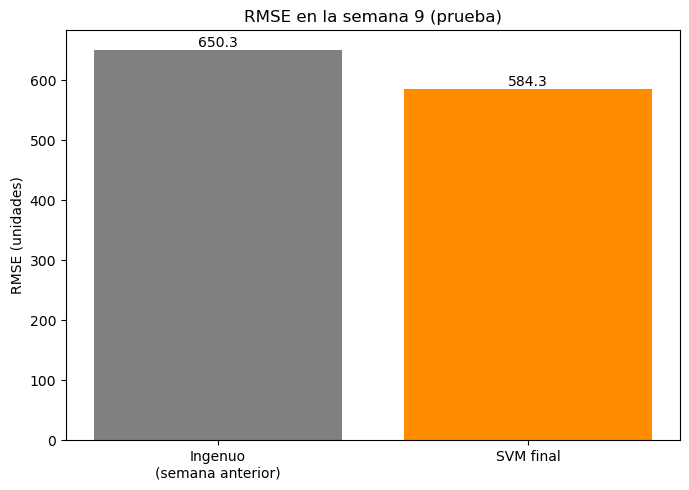

In [26]:
# Grafica: RMSE en la semana 9 (para las diapositivas)
nombres_barras = ['Ingenuo\n(semana anterior)', 'SVM final']
valores = [rmse_base, rmse_svm]
colores = ['gray', 'darkorange']
if RMSE_LSTM is not None:
    nombres_barras.append('LSTM final')
    valores.append(RMSE_LSTM)
    colores.append('steelblue')

plt.figure(figsize=(7, 5))
barras = plt.bar(nombres_barras, valores, color=colores)
for barra, valor in zip(barras, valores):
    plt.text(barra.get_x() + barra.get_width() / 2, valor, f'{valor:.1f}', ha='center', va='bottom')
plt.title('RMSE en la semana 9 (prueba)')
plt.ylabel('RMSE (unidades)')
plt.tight_layout()
plt.savefig('figuras/svm_rmse_final.png', dpi=150)
plt.show()

## 3.6 Ejemplos: real vs. predicho y pronóstico de la semana 10

Las mismas gráficas que con el LSTM: para 4 series mostramos la demanda real de las semanas 3 a 9, la predicción de la semana 9 (que sí podemos comparar) y el **pronóstico de la semana 10**, que nadie conoce todavía.

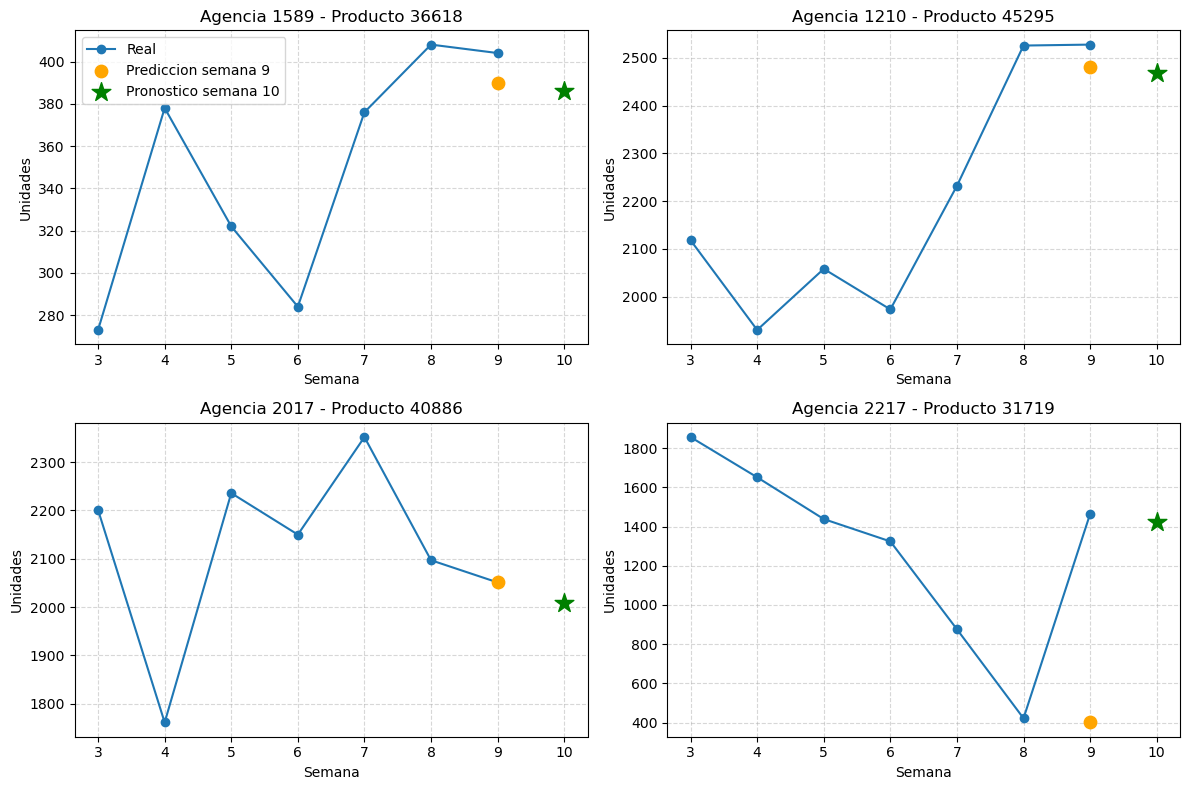

In [27]:
# Elegimos 4 series al azar entre las que venden al menos 100 unidades por semana (para que se vean bien)
grandes = np.where(demanda.mean(axis=1) >= 100)[0]
rng = np.random.default_rng(42)
ejemplos = rng.choice(grandes, size=min(4, len(grandes)), replace=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, i in zip(axes.ravel(), ejemplos):
    # Prediccion de la semana 9 (entrada: semanas anteriores a la 9), aplanada en una fila para la SVM
    X9 = datos_esc[i, 6 - MEJOR_N_SEM:6, :][:, MEJORES_VARS].reshape(1, -1)
    pred9 = a_unidades(modelo_final.predict(X9))[0]
    # Pronostico de la semana 10 (entrada: semanas anteriores a la 10, incluida la 9)
    X10 = datos_esc[i, 7 - MEJOR_N_SEM:7, :][:, MEJORES_VARS].reshape(1, -1)
    pred10 = a_unidades(modelo_final.predict(X10))[0]

    ax.plot(semanas, demanda[i], marker='o', label='Real')
    ax.scatter([9], [pred9], color='orange', s=80, zorder=3, label='Prediccion semana 9')
    ax.scatter([10], [pred10], color='green', marker='*', s=200, zorder=3, label='Pronostico semana 10')
    ax.set_title(f"Agencia {wide.index[i][0]} - Producto {wide.index[i][1]}")
    ax.set_xlabel('Semana')
    ax.set_ylabel('Unidades')
    ax.grid(linestyle='--', alpha=0.5)
axes.ravel()[0].legend()
plt.tight_layout()
plt.savefig('figuras/svm_ejemplos_prediccion.png', dpi=150)
plt.show()

# Parte 4. Funciones de predicción

**Dataset usado: completo, agregado.** Son las mismas funciones de la práctica del LSTM, pero usando la SVM. Como no hay fechas, se recibe el **número de semana**: de la 4 a la 9 (semanas conocidas, para comparar) o la **10** (pronóstico a futuro).

* `prediccion(agencia, producto, semana)`: demanda de un producto en una agencia.
* `prediccion_producto(producto, semana)`: demanda total de un producto (suma de todas sus agencias).
* `prediccion_lote(lista_productos, semana)`: lo mismo para varios productos a la vez.

In [28]:
idx = {par: i for i, par in enumerate(wide.index)}  # (Agencia_ID, Producto_ID) -> posicion

def prediccion(agencia, producto, semana):
    # Predice la demanda de 'semana' con las semanas anteriores (ventana y variables del modelo elegido)
    i = idx[(agencia, producto)]
    j = semana - 3
    X = datos_esc[i, j-MEJOR_N_SEM:j, :][:, MEJORES_VARS].reshape(1, -1)  # una fila para la SVM
    return float(a_unidades(modelo_final.predict(X))[0])

# Demo: 5 series, semana 9 (la real la conocemos)
for (ag, pr) in list(idx)[:5]:
    real = np.expm1(datos[idx[(ag, pr)], 6, DEM])
    print(f"Agencia {ag} | Producto {pr} | real: {real:.0f} | predicción: {prediccion(ag, pr, 9):.0f}")

Agencia 1110 | Producto 73 | real: 36 | predicción: 37
Agencia 1110 | Producto 108 | real: 688 | predicción: 714
Agencia 1110 | Producto 145 | real: 685 | predicción: 575
Agencia 1110 | Producto 202 | real: 676 | predicción: 635
Agencia 1110 | Producto 205 | real: 141 | predicción: 116


In [29]:
def prediccion_producto(producto, semana):
    # Posiciones de todas las series (agencias) que tienen este producto
    filas = [i for (ag, pr), i in idx.items() if pr == producto]
    if len(filas) == 0:
        return None  # el producto no tiene series con las 7 semanas completas
    j = semana - 3
    X = datos_esc[filas, j-MEJOR_N_SEM:j, :][:, :, MEJORES_VARS].reshape(len(filas), -1)
    pred = a_unidades(modelo_final.predict(X))
    return float(pred.sum())  # demanda total del producto en todas sus agencias

def prediccion_lote(lista_productos, semana):
    # Recibe varios productos y devuelve una prediccion por producto, en el mismo orden
    return [prediccion_producto(p, semana) for p in lista_productos]

In [30]:
# Demo: los 5 productos con mas demanda. Semana 9 (comparamos con lo real) y semana 10 (pronostico)
nombres = productos.drop_duplicates('Producto_ID').set_index('Producto_ID')['NombreProducto']
total_por_producto = wide['Demanda_uni_equil'].groupby(level='Producto_ID').sum().sum(axis=1)
productos_demo = total_por_producto.sort_values(ascending=False).head(5).index.tolist()
pred_9 = prediccion_lote(productos_demo, 9)
pred_10 = prediccion_lote(productos_demo, 10)

filas_resumen = []
for p, p9, p10 in zip(productos_demo, pred_9, pred_10):
    filas = [i for (ag, pr), i in idx.items() if pr == p]
    real_9 = np.expm1(datos[filas, 6, DEM]).sum()
    filas_resumen.append({'Producto': nombres[p], 'Real semana 9': round(real_9),
                          'Prediccion semana 9': round(p9), 'Pronostico semana 10': round(p10)})

pd.DataFrame(filas_resumen)

,Producto,Real semana 9,Prediccion semana 9,Pronostico semana 10
0,Nito 1p 62g Central BIM 2425,2744413,3028238,2633380
1,Nito 1p 62g BIM 1278,2595837,2835664,2536784
2,Rebanada 2p 55g BIM 1284,2299468,2664937,2276946
3,Gansito 1p 50g MTB MLA 43285,2073255,2026981,2030740
4,Bolsa Mini Rocko 40p 13g CU MLA 36610,1889011,1910767,1968157


# Resumen de resultados (para las diapositivas)

In [31]:
print(f"Series Agencia x Producto: {len(wide)}")
print(f"Ejemplos de entrenamiento: {N_MUESTRA} en los experimentos, {N_MUESTRA_FINAL} en el modelo final")
print()
print("Experimento 1 (validacion, semana 8):")
print(tabla_exp1.to_string(index=False))
print(f"Ingenuo en validacion: {rmse_ingenuo_val:.2f}")
print()
print("Experimento 2 - finetuning (validacion, semana 8):")
print(tabla_exp2.to_string(index=False))
print()
print("Experimento 3 - comparacion de kernels (validacion, semana 8):")
print(tabla_exp3.to_string(index=False))
print()
print(f"Modelo final: ventana {MEJOR_N_SEM}, {len(MEJORES_VARS)} variables, kernel {MEJOR_KERNEL}, "
      f"C {MEJOR_C}, gamma {MEJOR_GAMMA}")
print(f"Prueba (semana 9): RMSE SVM = {rmse_svm:.2f} | RMSE ingenuo = {rmse_base:.2f} | mejora = {mejora:.1f}%")
if RMSE_LSTM is not None:
    print(f"Prueba (semana 9): RMSE LSTM = {RMSE_LSTM:.2f}")

Series Agencia x Producto: 53714
Ejemplos de entrenamiento: 20000 en los experimentos, 40000 en el modelo final

Experimento 1 (validacion, semana 8):
 Ventana          Variables  Vectores de soporte  Segundos  RMSE validacion
       1     Originales (5)                11751      10.6           744.02
       1 Con temporales (7)                11596      10.1           775.73
       3     Originales (5)                11419      11.8           772.47
       3 Con temporales (7)                11325      13.7           750.92
Ingenuo en validacion: 690.28

Experimento 2 - finetuning (validacion, semana 8):
Kernel    C Gamma  Vectores de soporte  Segundos  RMSE validacion
   rbf 10.0   0.1                11777       9.6           583.49
   rbf  0.1   0.1                11818       8.6           587.50
   rbf  1.0   0.1                11797       8.9           595.61
linear 10.0     -                11889      16.7           595.81
linear  1.0     -                11891       7.2         